# Experiment 5: Reinforcement learning (Q-learning)
**Aim.** To formulate a navigation task as an MDP, implement Q-learning on a grid world, and measure the effect of the
exploration rate.

## Theory (summary)
$$Q(s,a) \leftarrow Q(s,a) + \alpha\big[r + \gamma \max_{a'} Q(s',a') - Q(s,a)\big]$$
The bracket is the temporal-difference error. Q-learning is **off-policy** and uses ε-greedy exploration.

In [1]:
%matplotlib inline
import os
import numpy as np
import matplotlib.pyplot as plt
os.makedirs('figs', exist_ok=True)
plt.rcParams['figure.dpi'] = 110

## Example 1: The environment

In [2]:
H, W = 5, 7
WALLS = {(1,2), (2,2), (3,2), (1,4), (2,4)}
GOAL, PIT, START = (0, W-1), (2, W-1), (H-1, 0)
A = [(-1,0), (1,0), (0,-1), (0,1)]            # up, down, left, right

def step(s, a):
    r, c = s; dr, dc = A[a]; nr, nc = r+dr, c+dc
    if not (0 <= nr < H and 0 <= nc < W) or (nr, nc) in WALLS:
        nr, nc = r, c                         # bumping a wall wastes the step
    ns = (nr, nc)
    if ns == GOAL: return ns, +10.0, True
    if ns == PIT:  return ns, -10.0, True
    return ns, -0.1, False                    # small cost per step

print('grid', H, 'x', W, '| goal', GOAL, '| pit', PIT, '| start', START)

grid 5 x 7 | goal (0, 6) | pit (2, 6) | start (4, 0)


## Example 2: Q-learning

In [3]:
def train(eps, episodes=600, alpha=0.5, gamma=0.95, seed=0):
    rng = np.random.default_rng(seed)
    Q = np.zeros((H, W, 4))
    curve = []
    for _ in range(episodes):
        s, total = START, 0.0
        for _ in range(120):                              # step cap
            if rng.random() < eps:
                a = rng.integers(4)                       # explore
            else:
                a = int(np.argmax(Q[s[0], s[1]]))         # exploit
            ns, r, done = step(s, a)
            total += r
            Q[s[0], s[1], a] += alpha * (
                r + gamma*np.max(Q[ns[0], ns[1]])*(not done) - Q[s[0], s[1], a])
            s = ns
            if done: break
        curve.append(total)
    return Q, np.array(curve)

## Example 3: Exploration rate, and reading the policy

eps=0.05: mean return over last 100 episodes = 8.86
eps=0.2: mean return over last 100 episodes = 8.86


eps=0.5: mean return over last 100 episodes = 7.44


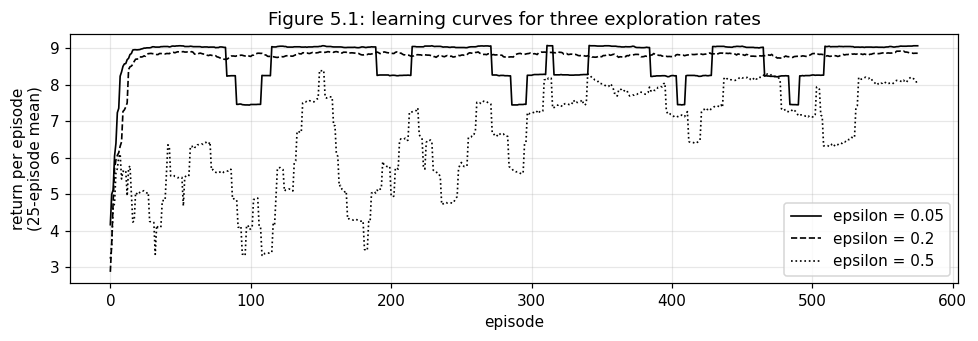

In [4]:
def smooth(v, k=25):
    return np.convolve(v, np.ones(k)/k, mode='valid')

Qs = {}
plt.figure(figsize=(9, 3.2))
styles = {0.05: '-', 0.20: '--', 0.50: ':'}
for eps in (0.05, 0.20, 0.50):
    Q, curve = train(eps)
    Qs[eps] = Q
    plt.plot(smooth(curve), styles[eps], color='k', lw=1.1, label=f'epsilon = {eps}')
    print(f'eps={eps}: mean return over last 100 episodes = {curve[-100:].mean():.2f}')
plt.xlabel('episode'); plt.ylabel('return per episode\n(25-episode mean)')
plt.title('Figure 5.1: learning curves for three exploration rates')
plt.legend(); plt.grid(alpha=0.3); plt.tight_layout(); plt.savefig('figs/fig5_1_learning.png'); plt.show()

Q, _ = train(0.20)
policy = np.argmax(Q, axis=2)                 # greedy action in every cell

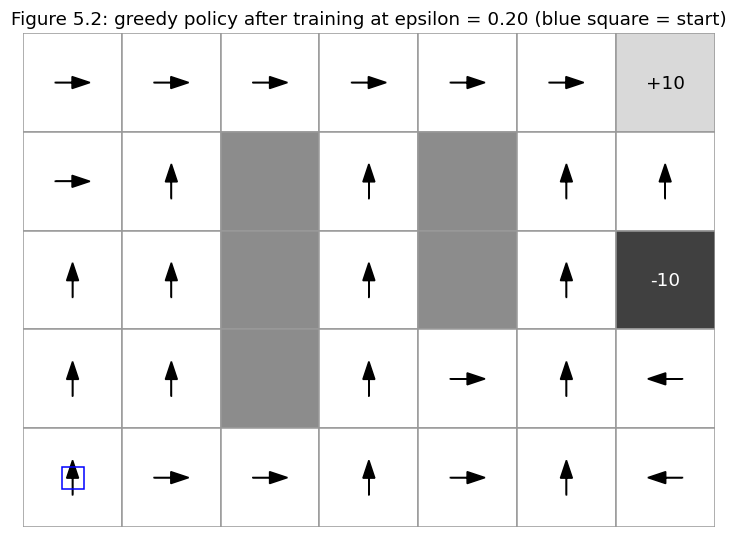

In [5]:
fig, ax = plt.subplots(figsize=(7, 5))
arrow = {0: (0, 0.35), 1: (0, -0.35), 2: (-0.35, 0), 3: (0.35, 0)}
for r in range(H):
    for c in range(W):
        y = H-1-r
        if (r, c) in WALLS:
            fc = '0.55'
        elif (r, c) == GOAL:
            fc = '0.85'
        elif (r, c) == PIT:
            fc = '0.25'
        else:
            fc = 'white'
        ax.add_patch(plt.Rectangle((c, y), 1, 1, fc=fc, ec='0.6'))
        if (r, c) == GOAL:
            ax.text(c+.5, y+.5, '+10', ha='center', va='center', fontsize=12)
        elif (r, c) == PIT:
            ax.text(c+.5, y+.5, '-10', ha='center', va='center', fontsize=12, color='w')
        elif (r, c) not in WALLS:
            dx, dy = arrow[policy[r, c]]
            ax.arrow(c+.5-dx/2, y+.5-dy/2, dx, dy, head_width=0.12, length_includes_head=True, color='k')
ax.plot(START[1]+.5, H-1-START[0]+.5, 's', ms=14, mfc='none', mec='b')
ax.set_xlim(0, W); ax.set_ylim(0, H); ax.set_aspect('equal'); ax.axis('off')
ax.set_title('Figure 5.2: greedy policy after training at epsilon = 0.20 (blue square = start)')
plt.tight_layout(); plt.savefig('figs/fig5_2_policy.png'); plt.show()

### Has the ε = 0.5 agent learned a worse policy? Run each greedy policy with no exploration

In [6]:
def greedy_rollout(Q, cap=50):
    s, total, path = START, 0.0, [START]
    for _ in range(cap):
        ns, r, done = step(s, int(np.argmax(Q[s[0], s[1]])))
        total += r; path.append(ns); s = ns
        if done: break
    return total, len(path)-1, s

print(f"{'eps':>5} {'greedy return':>14} {'steps':>6} {'ends at':>9}")
for eps, Qe in Qs.items():
    ret, n, end = greedy_rollout(Qe)
    print(f'{eps:>5} {ret:>14.2f} {n:>6} {str(end):>9}')

open_cells = [(r, c) for r in range(H) for c in range(W) if (r, c) not in WALLS | {GOAL, PIT}]
agree = np.mean([np.argmax(Qs[0.5][r, c]) == np.argmax(Qs[0.2][r, c]) for r, c in open_cells])
print(f'greedy actions identical (eps 0.5 vs 0.2) in {100*agree:.0f}% of open cells')

  eps  greedy return  steps   ends at
 0.05           9.10     10    (0, 6)
  0.2           9.10     10    (0, 6)
  0.5           9.10     10    (0, 6)
greedy actions identical (eps 0.5 vs 0.2) in 75% of open cells


## Observations to record
* Grid 5 × 7 with walls at (1,2), (2,2), (3,2), (1,4), (2,4).
* Rewards: goal +10, pit −10, −0.1 per step.
* Settings: α = 0.5, γ = 0.95, 600 episodes, step cap 120.
* The mean return over the last 100 episodes for each ε is printed above, and the extracted policy is shown in Figure 5.2.

## Discussion
* **Expected:** all three agents learn. Higher ε earns less during training because of the random actions.
* **Observed:** ε = 0.05 and 0.20 reach roughly the same final return, and ε = 0.50 is clearly lower.
  Run greedily, the ε = 0.50 agent reaches the goal by the same shortest route. Its *policy* is as good; only its *behaviour* while learning is worse.
  This is why ε is normally decayed.

## Viva questions (short answers)
1. $Q(s,a)$ is the current estimate. $r$ is the immediate reward, $\gamma\max Q(s',a')$ the discounted best future value and α the step size. The bracket is the TD error.
2. A terminal state has no future. Keeping the term bootstraps from values that will never be realised.
3. No. Its greedy rollout matches the others; it simply acts randomly half the time.
4. The −0.1 step cost rewards short routes. Without it, every path that eventually reaches the goal scores the same, since γ < 1 gives only a weak preference.
5. Off-policy means it learns the greedy policy's value (via max) while following an exploratory ε-greedy policy.